# Brain Tumor MRI Classification: Colab Demo

This notebook downloads the public four-class MRI dataset, compares a majority-class baseline with a ResNet50 transfer-learning model, evaluates both on the dataset's provided `Testing` folder, and inspects errors with optional Grad-CAM visualizations.

**Educational prototype only.** This project is not a medical device, diagnostic tool, or substitute for a qualified clinician. The images do not provide patient-level split metadata, so this notebook does not establish patient-independent generalization.

## Run from a fresh runtime
In Colab, select **Runtime → Run all** (or restart the runtime first). Training is intentionally short and can be increased with `EPOCHS`. The notebook uses the repository checkpoint only when this project has been cloned or uploaded into the current runtime; otherwise it trains a short fallback model.

In [1]:
%pip -q install kagglehub tensorflow numpy pandas matplotlib scikit-learn pillow

## 1. Download data and inspect its layout

KaggleHub downloads the dataset into its cache. The code searches recursively for the expected `Training` and `Testing` directories so it works whether the cache includes a `versions/2` parent or not.

In [2]:
from pathlib import Path
import os
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import kagglehub
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 4  # Short Colab-friendly fallback; increase only when compute permits.
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
AUTOTUNE = tf.data.AUTOTUNE
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

download_root = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))
print(f"KaggleHub cache: {download_root}")
training_candidates = [p for p in download_root.rglob("Training") if p.is_dir()]
dataset_root = next((p.parent for p in training_candidates if (p.parent / "Testing").is_dir()), None)
if dataset_root is None:
    raise FileNotFoundError(f"Could not find sibling Training/Testing directories under {download_root}")
TRAIN_DIR = dataset_root / "Training"
TEST_DIR = dataset_root / "Testing"
print(f"Dataset root: {dataset_root}")

def image_counts(split_dir):
    extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
    return {name: sum(1 for path in (split_dir / name).glob("*") if path.suffix.lower() in extensions)
            for name in CLASS_NAMES}

for split_name, split_dir in (("Training", TRAIN_DIR), ("Testing", TEST_DIR)):
    missing = [name for name in CLASS_NAMES if not (split_dir / name).is_dir()]
    if missing:
        raise ValueError(f"{split_name} is missing expected class folders: {missing}")
    print(f"{split_name} counts: {image_counts(split_dir)}")

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
KaggleHub cache: /kaggle/input/brain-tumor-mri-dataset
Dataset root: /kaggle/input/brain-tumor-mri-dataset
Training counts: {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}
Testing counts: {'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400}


,Training,Testing
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400


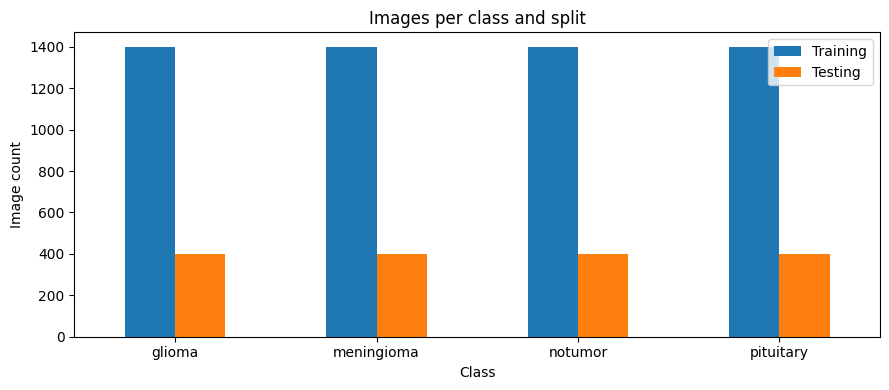

Found 5600 files belonging to 4 classes.
Using 4760 files for training.
Found 5600 files belonging to 4 classes.
Using 840 files for validation.
Found 1600 files belonging to 4 classes.
Training subset: 4760 | validation: 840 | held-out test: 1600


In [3]:
distribution = pd.DataFrame({
    split_name: image_counts(split_dir)
    for split_name, split_dir in (("Training", TRAIN_DIR), ("Testing", TEST_DIR))
}).reindex(CLASS_NAMES)
display(distribution)
distribution.plot(kind="bar", figsize=(9, 4), title="Images per class and split")
plt.xlabel("Class")
plt.ylabel("Image count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

train_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=CLASS_NAMES, image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, label_mode="int", validation_split=0.15,
    subset="training", seed=SEED, shuffle=True)
validation_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=CLASS_NAMES, image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, label_mode="int", validation_split=0.15,
    subset="validation", seed=SEED, shuffle=False)
test_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, class_names=CLASS_NAMES, image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, label_mode="int", shuffle=False)

assert train_raw.class_names == validation_raw.class_names == test_raw.class_names == CLASS_NAMES
preprocess = tf.keras.applications.resnet50.preprocess_input
train_ds = train_raw.map(lambda images, labels: (preprocess(images), labels), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
validation_ds = validation_raw.map(lambda images, labels: (preprocess(images), labels), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_raw.map(lambda images, labels: (preprocess(images), labels), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
y_train = np.concatenate([labels.numpy() for _, labels in train_raw], axis=0)
y_test = np.concatenate([labels.numpy() for _, labels in test_raw], axis=0)
print(f"Training subset: {len(y_train)} | validation: {sum(len(y.numpy()) for _, y in validation_raw)} | held-out test: {len(y_test)}")

## 2. Simple majority-class baseline

The baseline predicts the most common label in the training subset for every test image. It is intentionally simple and provides a useful floor for comparison.

In [4]:
train_counts = np.bincount(y_train, minlength=len(CLASS_NAMES))
majority_index = int(np.argmax(train_counts))
baseline_predictions = np.full(y_test.shape, majority_index, dtype=np.int64)
print(f"Majority class: {CLASS_NAMES[majority_index]} ({train_counts[majority_index]} training examples)")
print(f"Majority baseline test accuracy: {accuracy_score(y_test, baseline_predictions):.3f}")
print(classification_report(y_test, baseline_predictions, labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES, zero_division=0))

Majority class: glioma (1207 training examples)
Majority baseline test accuracy: 0.250
              precision    recall  f1-score   support

      glioma       0.25      1.00      0.40       400
  meningioma       0.00      0.00      0.00       400
     notumor       0.00      0.00      0.00       400
   pituitary       0.00      0.00      0.00       400

    accuracy                           0.25      1600
   macro avg       0.06      0.25      0.10      1600
weighted avg       0.06      0.25      0.10      1600



## 3. Load the repository checkpoint or train a short ResNet50 model

A normal Colab runtime does not contain this repository's model file. If you cloned/uploaded the project, a compatible checkpoint at `results/models/brain_tumor_model.keras` is reused. Otherwise, a frozen ImageNet ResNet50 backbone with a small classification head is trained briefly using only the Training/validation data. The held-out Testing folder is not used for training or model selection.

In [5]:
checkpoint_candidates = [
    Path("results/models/brain_tumor_model.keras"),
]
checkpoint_path = next((path for path in checkpoint_candidates if path.is_file()), None)

if checkpoint_path is not None:
    model = tf.keras.models.load_model(checkpoint_path, compile=False)
    if model.output_shape[-1] != len(CLASS_NAMES) or model.input_shape[1:3] != (IMG_SIZE, IMG_SIZE):
        raise ValueError(f"Checkpoint has incompatible input/output shape: {model.input_shape} -> {model.output_shape}")
    print(f"Loaded existing checkpoint: {checkpoint_path}")
else:
    backbone = tf.keras.applications.ResNet50(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    backbone.trainable = False
    inputs = backbone.input
    features = backbone.output
    features = tf.keras.layers.GlobalAveragePooling2D()(features)
    features = tf.keras.layers.Dropout(0.3)(features)
    outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax")(features)
    model = tf.keras.Model(inputs, outputs, name="brain_tumor_resnet50")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(train_ds, validation_data=validation_ds, epochs=EPOCHS,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)])
    print("Trained a short ResNet50 transfer-learning model.")

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/4
149/149 ━━━━━━━━━━━━━━━━━━━━ 74s 329ms/step - accuracy: 0.7185 - loss: 0.7301 - val_accuracy: 0.8786 - val_loss: 0.3550
Epoch 2/4
149/149 ━━━━━━━━━━━━━━━━━━━━ 18s 120ms/step - accuracy: 0.8653 - loss: 0.3582 - val_accuracy: 0.9357 - val_loss: 0.2558
Epoch 3/4
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 126ms/step - accuracy: 0.8905 - loss: 0.2963 - val_accuracy: 0.9107 - val_loss: 0.2784
Trained a short ResNet50 transfer-learning model.


Model: "brain_tumor_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,612,302 (90.07 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 16,394 (64.04 KB)

## 4. Evaluate both models on the held-out test set

These metrics describe this particular Kaggle split, not clinical performance. Test results are reported separately for the simple baseline and ResNet50 model.

50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 116ms/step

Majority baseline accuracy: 0.2500
ResNet50 test accuracy:      0.8544

ResNet50 classification report:
              precision    recall  f1-score   support

      glioma     0.9276    0.6725    0.7797       400
  meningioma     0.7077    0.8475    0.7713       400
     notumor     0.8957    0.9875    0.9394       400
   pituitary     0.9333    0.9100    0.9215       400

    accuracy                         0.8544      1600
   macro avg     0.8661    0.8544    0.8530      1600
weighted avg     0.8661    0.8544    0.8530      1600



,Model,Test accuracy
0,Majority baseline,0.250000
1,ResNet50,0.854375


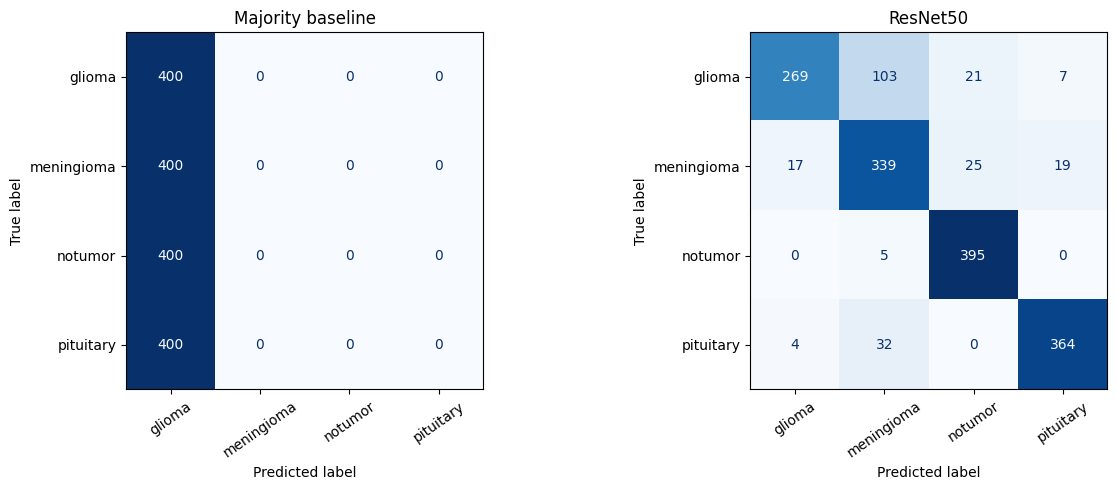

In [6]:
probabilities = model.predict(test_ds, verbose=1)
model_predictions = probabilities.argmax(axis=1)
baseline_acc = accuracy_score(y_test, baseline_predictions)
model_acc = accuracy_score(y_test, model_predictions)
print(f"\nMajority baseline accuracy: {baseline_acc:.4f}")
print(f"ResNet50 test accuracy:      {model_acc:.4f}")
print("\nResNet50 classification report:")
print(classification_report(y_test, model_predictions, labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES, zero_division=0, digits=4))
comparison = pd.DataFrame({
    "Model": ["Majority baseline", "ResNet50"],
    "Test accuracy": [baseline_acc, model_acc],
})
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, predictions, title in zip(axes, [baseline_predictions, model_predictions], ["Majority baseline", "ResNet50"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predictions, labels=range(len(CLASS_NAMES))),
                           display_labels=CLASS_NAMES).plot(ax=axis, cmap="Blues", colorbar=False, xticks_rotation=35)
    axis.set_title(title)
plt.tight_layout()
plt.show()

## 5. Inspect up to eight misclassified examples

The notebook displays up to eight actual test-set errors, with each original image beside a best-effort Grad-CAM overlay. Grad-CAM is a qualitative interpretability aid only—not proof of diagnosis, model correctness, or clinical validity. If visualization fails for an image, the original and prediction remain visible alongside a clear error message.

Misclassified images shown: 8


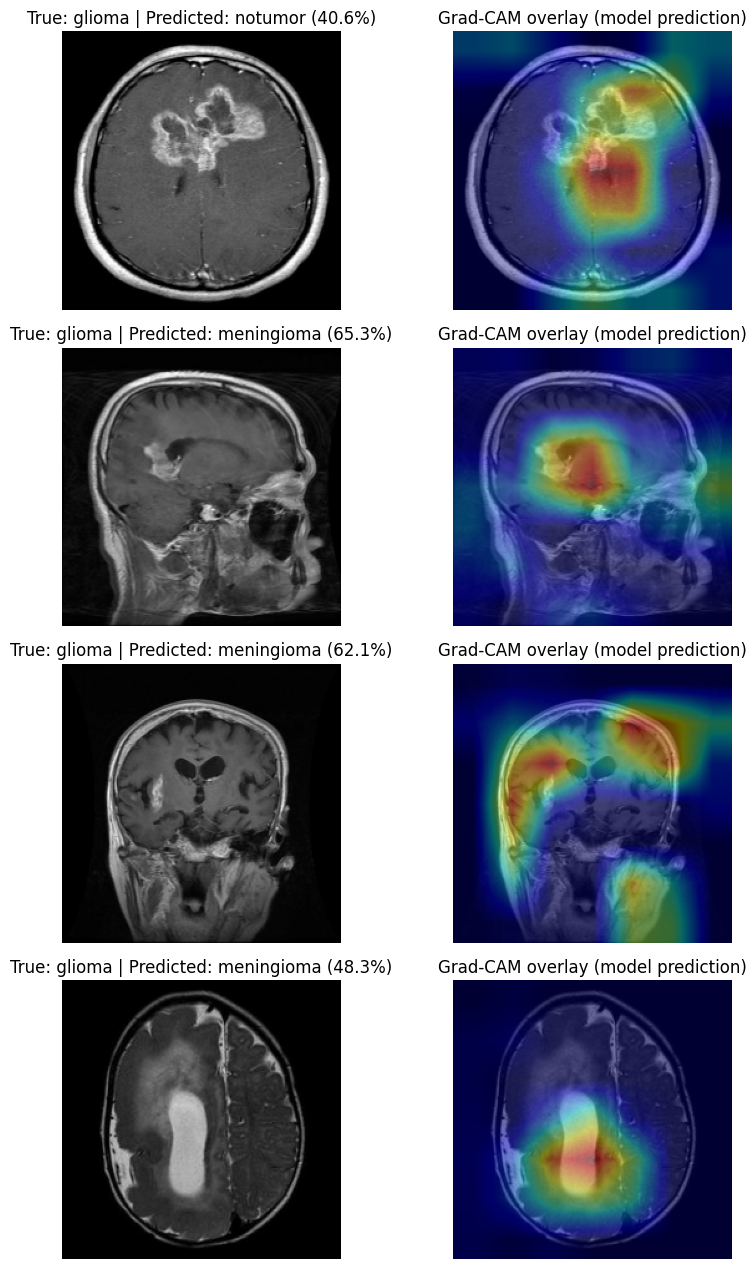

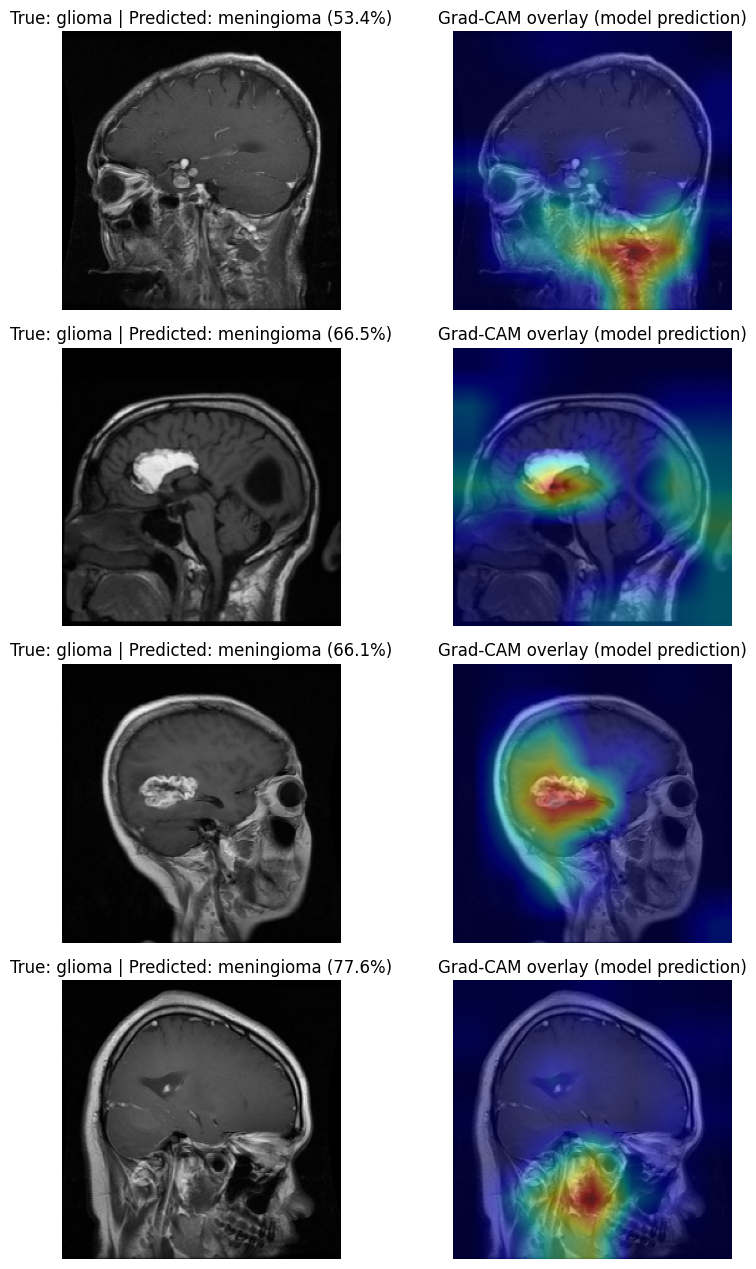

In [7]:
wrong_indices = np.flatnonzero(model_predictions != y_test)[:8]
print(f"Misclassified images shown: {len(wrong_indices)}")

def make_gradcam_overlay(image_rgb, class_index):
    conv_layer = model.get_layer("conv5_block3_out")
    grad_model = tf.keras.Model(model.inputs, [conv_layer.output, model.output])
    batch = preprocess(tf.convert_to_tensor(image_rgb[None, ...], dtype=tf.float32))
    with tf.GradientTape() as tape:
        conv_outputs, scores = grad_model(batch, training=False)
        class_score = scores[:, class_index]
    gradients = tape.gradient(class_score, conv_outputs)
    if gradients is None:
        raise ValueError("Gradients are disconnected for this model graph")
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.nn.relu(tf.reduce_sum(weights * conv_outputs, axis=-1))[0]
    heatmap /= tf.maximum(tf.reduce_max(heatmap), tf.keras.backend.epsilon())
    heatmap = tf.image.resize(heatmap[..., None], image_rgb.shape[:2]).numpy().squeeze()
    colored = plt.get_cmap("jet")(heatmap)[..., :3]
    return np.clip(0.6 * image_rgb / 255.0 + 0.4 * colored, 0, 1)

def load_test_image(index):
    image, label = next(iter(test_raw.unbatch().skip(int(index)).take(1)))
    if int(label.numpy()) != int(y_test[index]):
        raise ValueError(f"Test image order mismatch at index {index}")
    return np.asarray(image.numpy(), dtype=np.uint8)

for start in range(0, len(wrong_indices), 4):
    batch_indices = wrong_indices[start:start + 4]
    fig, axes = plt.subplots(len(batch_indices), 2, figsize=(9, 3.2 * len(batch_indices)), squeeze=False)
    for row, index in enumerate(batch_indices):
        true_name = CLASS_NAMES[int(y_test[index])]
        pred_index = int(model_predictions[index])
        confidence = float(probabilities[index, pred_index])
        image_rgb = load_test_image(index)
        axes[row, 0].imshow(image_rgb)
        axes[row, 0].set_title(f"True: {true_name} | Predicted: {CLASS_NAMES[pred_index]} ({confidence:.1%})")
        axes[row, 0].axis("off")
        try:
            axes[row, 1].imshow(make_gradcam_overlay(image_rgb, pred_index))
            axes[row, 1].set_title("Grad-CAM overlay (model prediction)")
        except Exception as error:
            axes[row, 1].text(0.5, 0.5, f"Grad-CAM unavailable for this image.\n{type(error).__name__}: {error}",
                              ha="center", va="center", wrap=True)
            axes[row, 1].set_title("Grad-CAM unavailable")
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.show()

## 6. Save the model

The final Keras model is written to `results/models/brain_tumor_model.keras`. After training and saving, copy or download this file into the same path in your project checkout; then the Streamlit app will load it using its default model path. In Colab, use the optional download command below and place the downloaded file in your local repository's `results/models/` folder.

In [8]:
MODEL_DIR = Path("results") / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
final_model_path = MODEL_DIR / "brain_tumor_model.keras"
model.save(final_model_path)
print(f"Saved model: {final_model_path.resolve()}")

# Optional Colab download:
# from google.colab import files
# files.download(str(final_model_path))

Saved model: /content/results/models/brain_tumor_model.keras


## Interpretation and limitations

- The majority-class baseline is a simple reference, not a medical comparator.
- The provided test split is evaluated once here, but the dataset supplies no patient identifiers; image-level splits cannot establish patient independence.
- Duplicate or near-duplicate images may occur across dataset partitions. Results should be treated as dataset-specific exploratory measurements.
- A short fallback training run is not equivalent to the repository's full experiment. Use the actual measured outputs above rather than assuming a benchmark.
- Grad-CAM overlays are qualitative and can be misleading. Neither model predictions nor visualizations should inform diagnosis, screening, treatment, or other clinical decisions.

**Dataset credit:** Masoud Nickparvar, *Brain Tumor MRI Dataset*, Kaggle, CC BY 4.0: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset

**Medical disclaimer:** For educational and hackathon demonstration purposes only. This prototype has not been clinically validated, is not a medical device, and must not be used for diagnosis or patient care. Qualified medical professionals must make all clinical decisions.